# Physical Games: Soccer Analysis

## Research Question
**In a penalty shootout consisting of 5 penalty kicks taken by a player with a historical penalty kick success rate of 75% ($p = 0.75$), what is the probability that the player scores exactly 4 goals? What is the probability that they score at least 3 goals?**

---

### Binomial Distribution Criteria:
1. **Fixed number of trials ($n$):** $n = 5$ penalty kicks.
2. **Two mutually exclusive outcomes:** Success (goal scored) or Failure (miss/saved).
3. **Constant probability of success ($p$):** $p = 0.75$ on each kick.
4. **Independent trials:** Each kick is independent of previous attempts.


## Simulation Design

### 1. The Random Variable ($X$)
- **Definition:** $X$ represents the total number of goals successfully scored by the player out of 5 penalty kick attempts in a single shootout.
- **Discrete Values:** $X \in \{0, 1, 2, 3, 4, 5\}$
  - $X = 0$: 0 goals scored (all 5 missed/saved)
  - $X = 1$: 1 goal scored
  - $X = 2$: 2 goals scored
  - $X = 3$: 3 goals scored
  - $X = 4$: 4 goals scored
  - $X = 5$: 5 goals scored (all 5 attempts successful)

### 2. A Single Trial and Its Possible Outcomes
- **Definition of a Single Trial (Bernoulli Trial):** A single trial is one individual penalty kick taken by the player.
- **Possible Outcomes:**
  - **Success ($1$):** The player scores a goal, with probability $p = 0.75$.
  - **Failure ($0$):** The player misses or the goalkeeper saves the kick, with probability $q = 1 - p = 0.25$.

A complete shootout consists of $n = 5$ independent Bernoulli trials, and the random variable $X$ is the sum of these individual outcomes:
$$X = \sum_{i=1}^{5} K_i, \quad K_i \sim \text{Bernoulli}(0.75)$$


## Step 1: Import Libraries and Define Parameters

We import `pandas`, `numpy`, and `matplotlib.pyplot`, and specify the simulation parameters:
- $n = 5$: Number of kicks per shootout
- $p = 0.75$: Probability of scoring each kick
- `num_simulations = 10,000`: Total shootouts simulated


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom
from IPython.display import display

# Set random seed for reproducibility
np.random.seed(42)

# Simulation Parameters
n_kicks = 5                 # Number of penalty kicks per shootout
p_goal = 0.75               # Historical success rate per kick
num_simulations = 10000     # Number of repeated shootouts


## Step 2: Simulate a Single Kick (Trial) and a Single Shootout

Here we represent a single trial (Bernoulli outcome) and combine 5 kicks into one shootout.


In [2]:
# 1 = Goal (Success), 0 = Miss/Saved (Failure)
single_shootout = np.random.choice([1, 0], size=n_kicks, p=[p_goal, 1 - p_goal])

print(f"Results of individual kicks in one shootout: {single_shootout}")
print(f"Total goals scored (X): {single_shootout.sum()} / {n_kicks}")


Results of individual kicks in one shootout: [1 0 1 1 1]
Total goals scored (X): 4 / 5


## Step 3: Run Monte Carlo Simulation across 10,000 Shootouts

We generate all 10,000 shootouts and store them in a **Pandas DataFrame** where:
- Each row represents a full shootout.
- Each column `Kick_1` through `Kick_5` records the individual kick outcome (1 = Goal, 0 = Miss).
- The column `Goals_Scored` records the random variable $X$.


In [3]:
# Simulate 10,000 shootouts of 5 kicks each using binomial random variates
kick_matrix = np.random.binomial(n=1, p=p_goal, size=(num_simulations, n_kicks))

# Build Pandas DataFrame
columns = [f"Kick_{i+1}" for i in range(n_kicks)]
df_shootouts = pd.DataFrame(kick_matrix, columns=columns)

# Add total goals scored (Random Variable X)
df_shootouts["Goals_Scored"] = df_shootouts.sum(axis=1)

# Display first 5 rows
df_shootouts.head()


Out[0]: 
   Kick_1  Kick_2  Kick_3  Kick_4  Kick_5  Goals_Scored
0       1       1       0       1       1             4
1       1       0       0       1       1             3
2       1       1       1       1       1             5
3       1       1       1       1       1             5
4       0       1       1       1       1             4


## Step 4a: Calculate Theoretical Probabilities

Assuming independent kicks and a constant scoring probability, $X \sim \mathrm{Binomial}(5, 0.75)$.

$$P(X=k)=\binom{5}{k}(0.75)^k(0.25)^{5-k}.$$

For exactly 4 goals, use $k=4$. For at least 3 goals, add the probabilities for 3, 4, and 5 goals.

In [4]:
# Theoretical probabilities come from the binomial model.
x_vals = np.arange(n_kicks + 1)
theoretical_probabilities = binom.pmf(x_vals, n_kicks, p_goal)
theo_p_exact_4 = theoretical_probabilities[4]
theo_p_at_least_3 = theoretical_probabilities[3:].sum()

print(f"Theoretical P(X = 4): {theo_p_exact_4:.6f} ({theo_p_exact_4:.2%})")
print(f"Theoretical P(X >= 3): {theo_p_at_least_3:.6f} ({theo_p_at_least_3:.2%})")

Theoretical P(X = 4): 0.395508 (39.55%)
Theoretical P(X >= 3): 0.896484 (89.65%)


## Step 4b: Calculate Empirical Probabilities

An empirical probability is the number of simulated shootouts satisfying an event divided by the total number of simulated shootouts. These estimates use simulated results, not observations of real players.

In [5]:
goals = df_shootouts["Goals_Scored"]
count_exact_4 = (goals == 4).sum()
count_at_least_3 = (goals >= 3).sum()
sim_p_exact_4 = count_exact_4 / len(goals)
sim_p_at_least_3 = count_at_least_3 / len(goals)

print(f"Exactly 4 goals: {count_exact_4:,} / {len(goals):,} = {sim_p_exact_4:.2%}")
print(f"At least 3 goals: {count_at_least_3:,} / {len(goals):,} = {sim_p_at_least_3:.2%}")

Exactly 4 goals: 3,947 / 10,000 = 39.47%
At least 3 goals: 9,001 / 10,000 = 90.01%


## Step 4c: Compare the Results

Include every possible goal total, even if an outcome does not occur in the simulation.

In [6]:
counts = goals.value_counts().reindex(x_vals, fill_value=0).sort_index()
freq_table = pd.DataFrame({
    "Count": counts,
    "Simulated_Probability": counts / len(goals),
    "Theoretical_Probability": theoretical_probabilities,
})
freq_table.index.name = "Goals_Scored"
display(freq_table)

comparison = pd.DataFrame({
    "Event": ["Exactly 4 goals", "At least 3 goals"],
    "Theoretical": [theo_p_exact_4, theo_p_at_least_3],
    "Empirical (simulation)": [sim_p_exact_4, sim_p_at_least_3],
})
comparison["Absolute difference"] = abs(comparison["Empirical (simulation)"] - comparison["Theoretical"])
display(comparison.style.format({column: "{:.4%}" for column in comparison.columns[1:]}))
print("Small differences are expected because the simulation uses a finite random sample.")

Small differences are expected because the simulation uses a finite random sample.


,Count,Simulated_Probability,Theoretical_Probability
Goals_Scored,,,
0,12,0.0012,0.000977
1,167,0.0167,0.014648
2,820,0.0820,0.087891
3,2637,0.2637,0.263672
4,3947,0.3947,0.395508
5,2417,0.2417,0.237305


,Event,Theoretical,Empirical (simulation),Absolute difference
0,Exactly 4 goals,39.5508%,39.4700%,0.0808%
1,At least 3 goals,89.6484%,90.0100%,0.3616%


## Step 5: Prepare Data and Seaborn Styling for Visualization

We import `seaborn` alongside `matplotlib.pyplot`, configure the styling theme, and transform the frequency table into a tidy format ideal for Seaborn plotting.


In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configure Seaborn aesthetic style
sns.set_theme(style="whitegrid", palette="deep")

# Transform frequency table into tidy DataFrame for Seaborn
df_plot = freq_table.reset_index().rename(columns={"index": "Goals_Scored"})
df_tidy = df_plot.melt(
    id_vars="Goals_Scored",
    value_vars=["Simulated_Probability", "Theoretical_Probability"],
    var_name="Distribution",
    value_name="Probability"
)
df_tidy["Distribution"] = df_tidy["Distribution"].map({
    "Simulated_Probability": "Simulated (Pandas)",
    "Theoretical_Probability": "Theoretical (Binomial)"
})

df_tidy.head(6)


Out[0]: 
   Goals_Scored        Distribution  Probability
0             0  Simulated (Pandas)       0.0012
1             1  Simulated (Pandas)       0.0167
2             2  Simulated (Pandas)       0.0820
3             3  Simulated (Pandas)       0.2637
4             4  Simulated (Pandas)       0.3947
5             5  Simulated (Pandas)       0.2417


## Step 6: Graph the Probability Distribution

Compare theoretical probabilities with empirical frequencies from 10,000 simulated shootouts. The labels show the theoretical mean and standard deviation and their empirical counterparts.

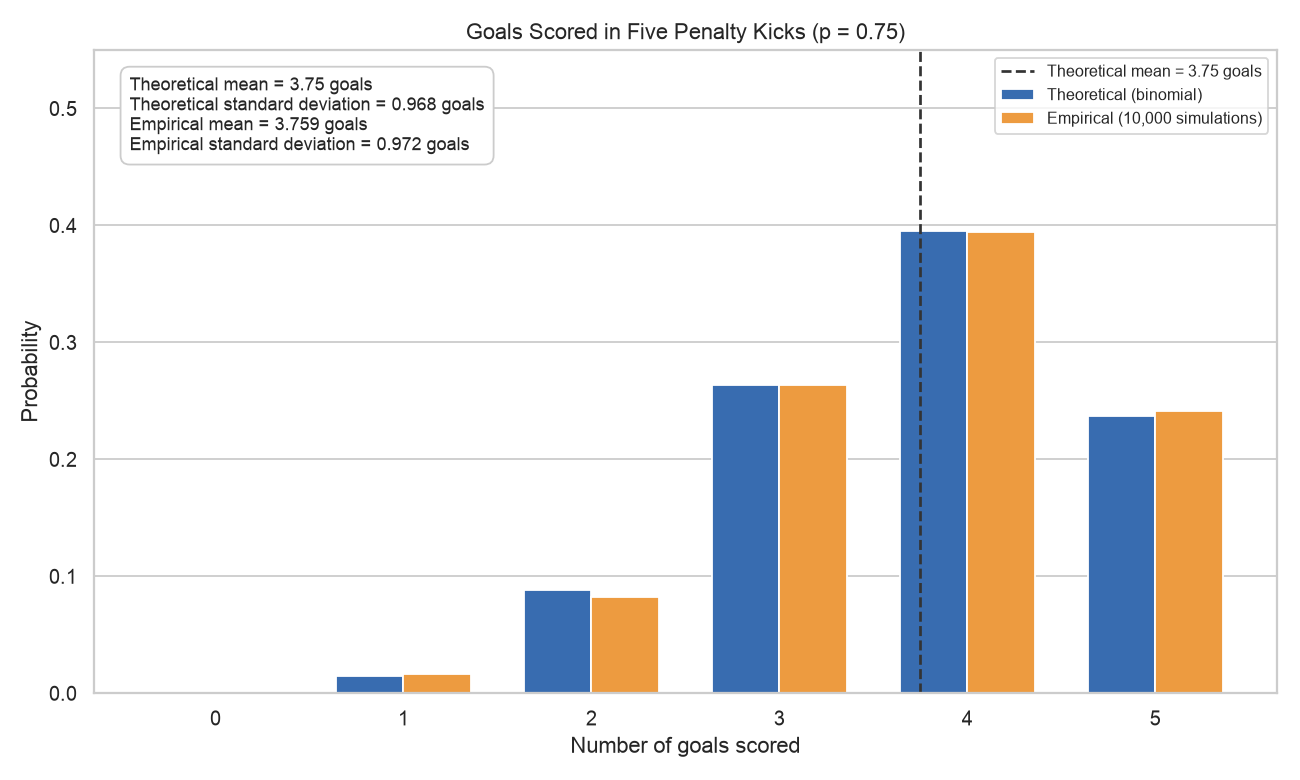

In [8]:
# Summary statistics for the theoretical and simulated distributions.
theo_mean = n_kicks * p_goal
theo_sd = np.sqrt(n_kicks * p_goal * (1 - p_goal))
emp_mean = goals.mean()
emp_sd = goals.std(ddof=0)  # SD of the simulated empirical distribution

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.36
ax.bar(x_vals - width / 2, freq_table["Theoretical_Probability"],
       width, label="Theoretical (binomial)", color="#386cb0")
ax.bar(x_vals + width / 2, freq_table["Simulated_Probability"],
       width, label="Empirical (10,000 simulations)", color="#ed9b40")
ax.axvline(theo_mean, color="#333333", linestyle="--", linewidth=1.5,
           label=f"Theoretical mean = {theo_mean:.2f} goals")
ax.text(0.03, 0.96,
        f"Theoretical mean = {theo_mean:.2f} goals\n"
        f"Theoretical standard deviation = {theo_sd:.3f} goals\n"
        f"Empirical mean = {emp_mean:.3f} goals\n"
        f"Empirical standard deviation = {emp_sd:.3f} goals",
        transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc"))
ax.set(title="Goals Scored in Five Penalty Kicks (p = 0.75)",
       xlabel="Number of goals scored", ylabel="Probability",
       xticks=x_vals, ylim=(0, 0.55))
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## Step 7: Plot the Cumulative Distribution Function (CDF)

To visualize cumulative probability $P(X \le k)$ and highlight our question of scoring at least 3 goals ($P(X \ge 3)$), we plot both the Seaborn empirical CDF and the theoretical step CDF.


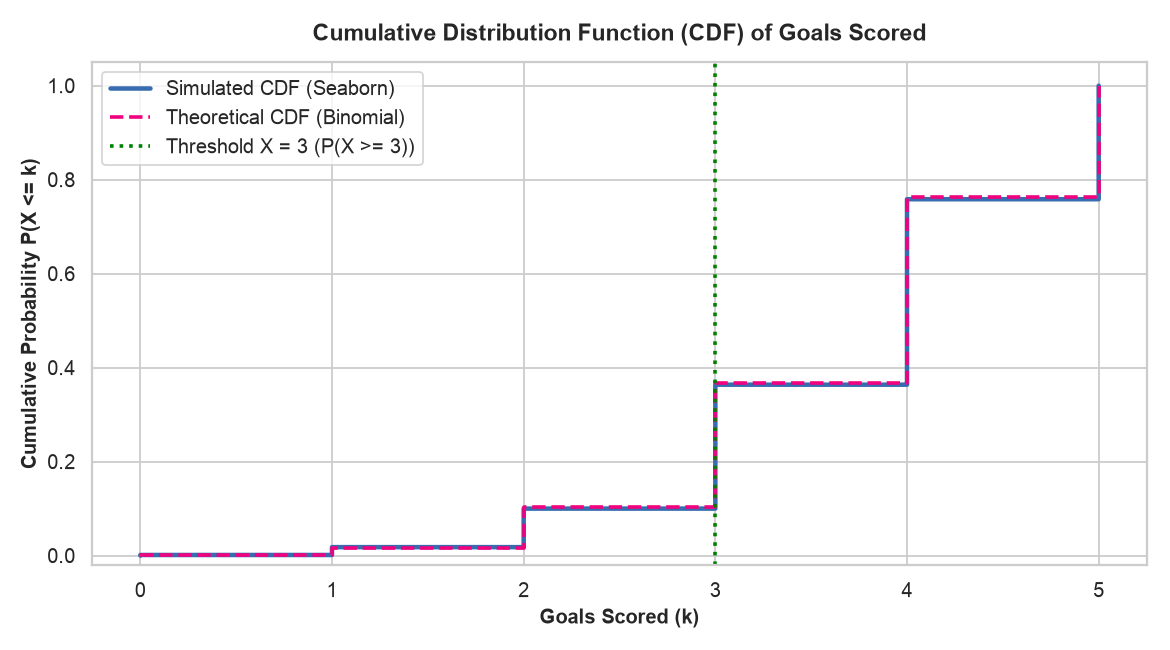

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

# Seaborn empirical CDF
sns.ecdfplot(data=df_shootouts, x="Goals_Scored", label="Simulated CDF (Seaborn)", ax=ax, color="#386cb0", linewidth=2.5)

# Theoretical CDF using Scipy binom
k_vals = np.arange(0, 6)
theo_cdf = binom.cdf(k_vals, n_kicks, p_goal)
ax.step(k_vals, theo_cdf, where="post", label="Theoretical CDF (Binomial)", color="#f0027f", linestyle="--", linewidth=2)

# Highlight region of interest: P(X >= 3)
ax.axvline(x=3, color="green", linestyle=":", linewidth=2, label="Threshold X = 3 (P(X >= 3))")

ax.set_title("Cumulative Distribution Function (CDF) of Goals Scored", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Goals Scored (k)", fontsize=11, fontweight="bold")
ax.set_ylabel("Cumulative Probability P(X <= k)", fontsize=11, fontweight="bold")
ax.set_xticks(range(0, 6))
ax.set_ylim(-0.02, 1.05)
ax.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.show()


## Conclusion

For a player with a 75% chance of scoring each of five independent penalty kicks, the **theoretical probability of exactly 4 goals is 39.55%**. In the 10,000 simulated shootouts, exactly 4 goals occurred 3,947 times, giving an **empirical probability of 39.47%**. The theoretical probability of **at least 3 goals is 89.65%**, compared with an empirical probability of **90.01%** (9,001 out of 10,000 shootouts).

The distribution graph shows that 4 goals is the most likely individual outcome. The bars for 3, 4, and 5 goals together account for approximately 90% of the probability, supporting the conclusion that scoring at least 3 goals is very likely. The theoretical mean is **3.75 goals**, and the theoretical standard deviation is approximately **0.968 goals**; these describe the center and spread of the distribution. Most of the probability is concentrated between 3 and 5 goals, with a tail toward lower goal totals.

The empirical bars closely match the theoretical bars, supporting the simulated estimates of both requested probabilities. Small differences are expected from random variation in a finite simulation. These empirical results come from a simulation, not real player observations, and the conclusions depend on independent kicks and a constant 75% scoring probability.